# Week 10; Tower Detective 🕵️‍♀️🗼
**GGS 662 Agentic GeoAI | Human labelling, evidence, and agents**

**Research question: Can an agent help us label cell-tower sites, and know when to ask a human?**

Last week we asked an agent to improve a detector. This week, we give it a different job: **check the evidence before trusting a label**.

First, you are the detective. You will use a browser tool to label **20 aerial images**. Then we will use a supplied set of **60 labelled images** to develop and evaluate an evidence-using agent. Your 20 are a subset of those 60. Finish what you can; your manual work will not hold up the rest of the lesson.

Our route: **👀 inspect → ✏️ label → 🧰 gather evidence → 🤖 investigate → ⚖️ compare**.

By the end, you should be able to explain the difference between a detector proposal, a human reference, and an agent decision—and show when additional evidence helps.

## 1. What are we actually looking for? 🗼

The target is a **freestanding cell-tower ground site**. Use a rectangle around the visible tower-site footprint, including its associated ground compound where identifiable, following the supplied reviewed examples. Do not extend a box just to capture a long shadow. Existing reference boxes can vary; flag convention disagreements instead of silently changing them.

| What is in the image? | What should we do? |
| --- | --- |
| A freestanding cell-tower site | Mark **positive** and draw its box. Box every target you can identify. |
| A water tower, electrical pylon, or rooftop support—even with antennas | Exclude that structure. Mark negative only if there is no actual target elsewhere in the chip. |
| Trees, low detail, or conflicting evidence prevent a decision | Mark **uncertain**. Being honest is part of the job! |

These are **cell-tower sites**, unlike Week 9's electricity transmission towers. A tall thing is not automatically our target. 🔎

**Quick discussion:** Does an OSM point labelled “cell tower” prove that the tower was present when the aerial image was taken?

### Set up our detective desk 🧰

Use a local Python kernel. From a terminal in `week10`, install the lesson dependencies with `python -m pip install -r requirements-demo.txt`. Open this notebook and select that environment.

The core lesson uses bundled RGB images and saved source evidence. It needs no data-service API key, GPU, model weights, or live downloads. Your local coding assistant needs its usual access for the agent activity; that is separate from the offline notebook.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'week10/scripts/lesson.py').is_file() or (p / 'scripts/lesson.py').is_file())
ROOT = ROOT / 'week10' if (ROOT / 'week10/scripts/lesson.py').is_file() else ROOT
sys.path.insert(0, str(ROOT))
print('Detective desk:', ROOT)

Detective desk: C:\Users\eoughton\Desktop\Github\Agentic-GeoAI\week10


Load the helpers and check that all 60 images are present and unchanged. This checks files, not the scientific correctness of every reference label.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts import lesson as lab

display(lab.validate_bundle())

{'images': 60,
 'manual_images': 20,
 'image_checksums': 'passed',
 'mode': 'offline classroom comparison; references supplied'}

## 2. Your first case: 20 images, no hints ✏️

The manual exercise initially shows **imagery only**: no proposal boxes, FCC records, or reference answers. Inspect the whole chip, not just its centre.

The image IDs are deliberately boring. `site_014` does not tell you whether a tower is present. Your job is to decide! Below are three of the images you will review, without labels.

Your mission: 20 images. Time budget: about 15 minutes.


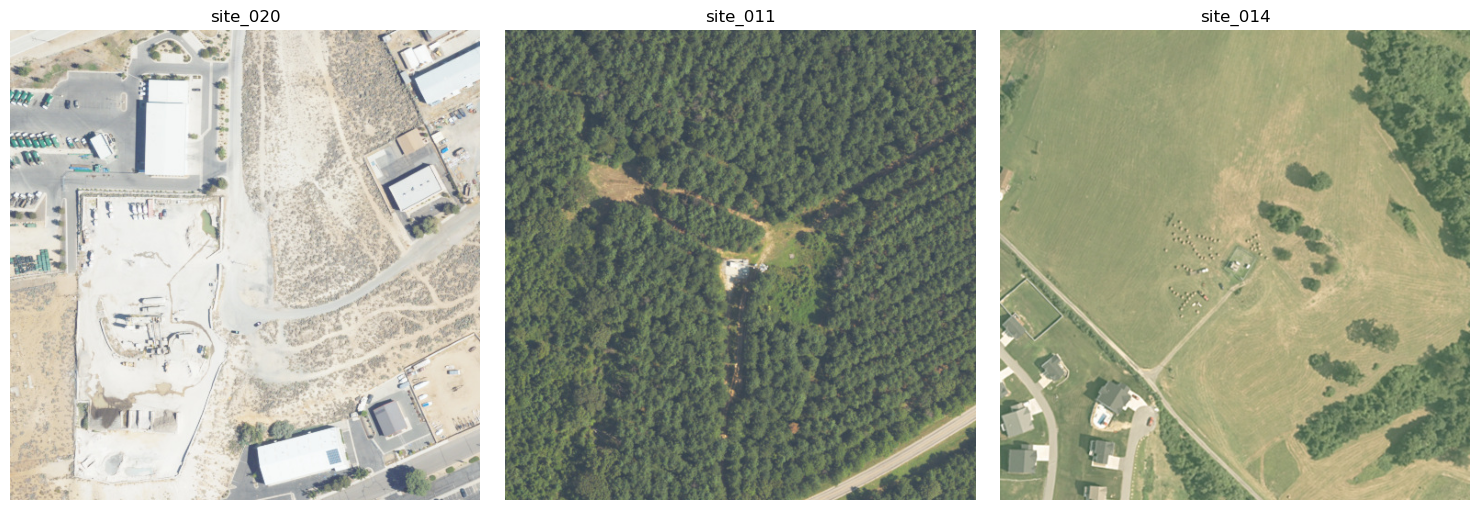

In [3]:
manual_ids = lab.load(ROOT / 'data/manual20/ids.json')
preview_ids = [manual_ids[i] for i in (0, 3, 4)]
print(f'Your mission: {len(manual_ids)} images. Time budget: about 15 minutes.')
lab.show_images(preview_ids)
plt.show()

### Make the browser tool yours 🌐

We have supplied a working **VIA-style HTML interface**, inspired by the [VGG Image Annotator](https://robots.ox.ac.uk/~vgg/software/via/index.html). It runs locally and exports VIA 2-style JSON; it is a small teaching interface, not the upstream VIA application.

Run the next cell, then open the printed `manual20.html` file in your browser. You can double-click it in your file manager. Keep it inside the lesson folder so it can find its images.

**Optional 5-minute coding-agent mission:** open your local agent panel with `week10` as the workspace and paste:

> Read `review/template.html` and `scripts/build_review.py`. Explain how images, boxes and labels are saved. Then customize the page with a team name and a helpful keyboard shortcut. Keep the target definition, original pixel coordinates, export schema, and positive/negative box checks intact. Do not open reference labels. Rebuild `review/manual20.html` and check the change. Keep a working copy so we can still complete the lab if customization fails.

This is a small interface-building task. We already have a working fallback, so no one gets stuck building buttons for an hour. 🙂

In [4]:
from scripts.build_review import build

review_page = build()
print('Open this file in your browser:', review_page)
print('Browser address:', review_page.as_uri())

Open this file in your browser: C:\Users\eoughton\Desktop\Github\Agentic-GeoAI\week10\review\manual20.html
Browser address: file:///C:/Users/eoughton/Desktop/Github/Agentic-GeoAI/week10/review/manual20.html


### Ready, set, label! ⏱️

1. Drag to draw a rectangle. Click a box and use **Delete selected** if you need to remove it.
2. Choose **positive**, **negative**, or **uncertain**. Positive needs a box; negative needs none.
3. Add a brief note when something is difficult. What did you actually see?
4. Choose **Save decision & next**. Use **Export reviewed JSON** frequently.
5. When 15 minutes are up, export even if you have not finished all 20.

The browser remembers progress when storage is available, but **the downloaded JSON is your saved file**. Use **Resume from JSON** to restore it. Copy your export to `week10/student_work/my_tower_labels.json`.

**Pause here before running Section 3.** No peeking at the supplied answers until you have exported your first attempt. 🙈

## 3. Compare with a supplied human review ⚖️

Now we can reveal the references. They are existing human-reviewed annotations from the source project, **not infallible ground truth**. Some images remain uncertain. If your decision differs, inspect the image and annotation convention before declaring either reviewer wrong.

The next cell is optional: it reads your export if you copied it into `student_work`. Unreviewed images are kept separate, so running out of time does not turn them into negatives.

In [5]:
manual_file = ROOT / 'student_work/my_tower_labels.json'
if manual_file.exists():
    manual_comparison = lab.compare_manual(lab.import_manual(manual_file))
    display(manual_comparison)
else:
    print('No manual export found yet. You can add it later; continue with the supplied references.')

No manual export found yet. You can add it later; continue with the supplied references.


Green boxes below are **supplied human annotations**, not predictions. Pick a few IDs from your manual review and compare the decisions and box footprints.

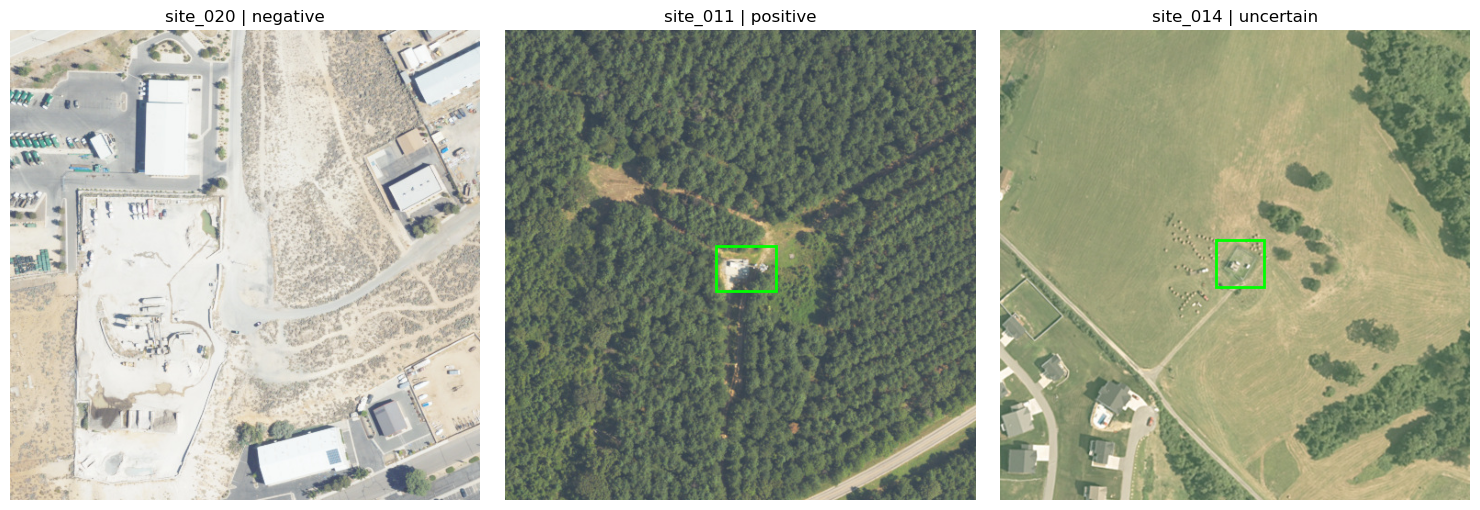

In [6]:
lab.show_images(preview_ids, reference=True)
plt.show()

### Keep moving: the complete labelled set is ready 📦

We supply **60 images and their reference annotations** in the repository. Your manual 20 are included in these 60. You do not have to finish labelling everything to continue.

The teaching selection contains 20 likely easy positives, 20 challenging cases (10 reviewed positives and 10 uncertain), and 20 reviewed negatives. “Likely easy” is a sampling description based partly on historical detector scores, not a guarantee. These groups are hidden from the agent-facing inputs.

This balanced sample is for learning and comparing approaches. Some examples overlap historical model training/validation, and proposal caches come from different historical runs. **Do not describe these results as an independent national accuracy test or a clean single-model benchmark.** Source membership and selection records are in `data/reference/provenance.json`.

In [7]:
reference = pd.read_csv(ROOT / 'data/reference/labels.csv')
display(reference.groupby('status').size().rename('images').to_frame())
print('VIA-style reference project:', ROOT / 'data/reference/labels_via.json')

,images
status,
negative,20
positive,30
uncertain,10


VIA-style reference project: C:\Users\eoughton\Desktop\Github\Agentic-GeoAI\week10\data\reference\labels_via.json


## 4. What can another data source tell us? 🧩

An aerial image is one piece of evidence. A detector adds a proposal. OSM supplies candidate tags. FCC records can describe nearby registered structures. Each source also has blind spots.

| Evidence | Useful question | A tempting mistake |
| --- | --- | --- |
| Aerial image | What is visible, and when was it captured? | Treating poor visibility as absence |
| Detector proposal | Where might the target be? | Treating its score as the probability of being right |
| OSM tags | Why was this candidate selected? | Treating the candidate-selection source as independent confirmation |
| FCC registration | Is a compatible registered structure nearby? | Assuming every cell tower must be registered, or a nearby record proves cellular use |

The FCC does not require every antenna structure to be registered ([FCC discussion](https://docs.fcc.gov/public/attachments/FCC-10-53A1_Rcd.pdf)). A missing record cannot establish absence. Construction and imagery dates can also disagree.

Our lesson uses **cached evidence**. Some channels were never retrieved for some images: `available=False` means missing evidence, not “we searched and found nothing”.

**No downloading during class! 📂** We prepared local CSV tables for the 60 candidates. Load them once, then filter by site ID. The agent's tools read the same bundled evidence; choosing a tool means choosing which local evidence to inspect, not making a live API request. OpenCellID is not included in this version.

In [8]:
sites = pd.read_csv(ROOT / 'data/tables/sites.csv')
osm = pd.read_csv(ROOT / 'data/tables/osm_candidates.csv', keep_default_na=False)
fcc = pd.read_csv(ROOT / 'data/tables/fcc_matches.csv', dtype={'registration': 'string', 'unique_id': 'string'})
print(f'Loaded {len(sites)} candidates, {len(osm)} OSM rows, and {len(fcc)} nearby FCC records. No downloads needed!')
display(sites.groupby('fcc_status').size().rename('sites').to_frame())

Loaded 60 candidates, 60 OSM rows, and 68 nearby FCC records. No downloads needed!


,sites
fcc_status,
matches_found,39
no_matches_in_cached_search,21


Open one evidence-rich case. Orange boxes are saved detector proposals, generated on the original source imagery—not fresh predictions on the compressed classroom JPEG.

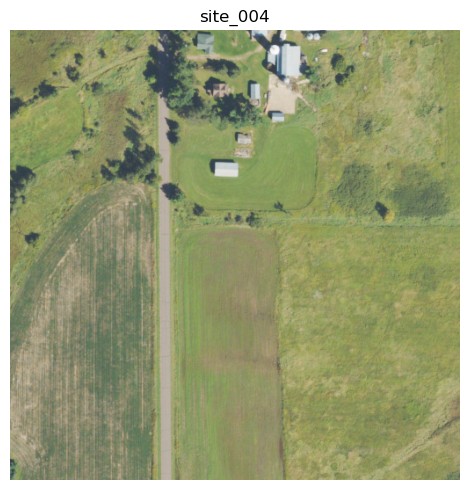

In [9]:
case_id = 'site_004'
case = lab.evidence(case_id)
lab.show_images([case_id], proposals=True, columns=1)
plt.show()

Read the source details. A short distance is a possible spatial match; it does not settle the target definition or the acquisition-date question.

In [10]:
display(pd.Series(case['imagery'], name='imagery'))
display(osm.loc[osm['id'] == case_id, ['id', 'man_made', 'tower_type', 'mobile_phone', 'power']])
display(sites.loc[sites['id'] == case_id, ['id', 'fcc_status', 'fcc_search_radius_m']])
display(fcc.loc[fcc['id'] == case_id, ['id', 'registration', 'distance_m', 'height_structure_m', 'constructed_date', 'constructed_after_naip']])

path                     images/site_004.jpg
date               2024-08-31T00:00:00+00:00
resolution_m                             0.6
source_id       m_4509239_ne_15_060_20240831
latitude                           45.480202
longitude                         -92.165828
Name: imagery, dtype: object

,id,man_made,tower_type,mobile_phone,power
3,site_004,mast,communication,yes,


,id,fcc_status,fcc_search_radius_m
3,site_004,matches_found,1000


,id,registration,distance_m,height_structure_m,constructed_date,constructed_after_naip
5,site_004,1326645,1.9,76.2,11/27/2024,True


**Partner challenge 💬:** Give one reason this evidence supports a decision, and one reason it might mislead you. What additional observation would actually change your mind?

For example, a record built after the image date cannot confirm that the structure is visible in that image. A water tank carrying antennas still falls outside our target definition.

## 5. Give the agent something to beat 📏

We start with two deliberately simple baselines:

- **Detector only:** confirm at a maximum proposal score ≥ 0.70, reject below 0.25, and request review in between. Missing detector output requests review. This rule can miss real targets when the detector finds nothing.
- **Fixed evidence rules:** confirm only when a high detector score agrees with a nearby, dated FCC record and no excluded-support tag conflicts. Otherwise request review. This conservative rule may leave a lot of work for humans.

The thresholds are illustrative, not tuned or calibrated against these answers. The cached proposals have different source histories, so this is an example of decision policies over saved evidence.

In [11]:
detector_predictions = lab.baseline('detector')
rules_predictions = lab.baseline('evidence_rules')
baseline_results = pd.DataFrame([lab.score(detector_predictions), lab.score(rules_predictions)], index=['Detector only', 'Fixed evidence rules'])
display(baseline_results)

,evaluated,automatic,request_review,coverage,resolved_automatic,wrong_automatic,false_confirms,false_rejections,selective_error,unresolved_routing
Detector only,60,37,23,0.616667,34,2,0,2,0.058824,"{'no_target': 1, 'confirm': 2, 'request_review..."
Fixed evidence rules,60,20,40,0.333333,20,0,0,0,0.000000,{'request_review': 10}


### Accuracy alone can hide the interesting bit 🎭

An agent that sends every image to a human makes no automatic mistakes—but saves no reviewing effort. We need to show both:

**Automatic coverage = automatic decisions / all images.**

**Selective error = wrong automatic decisions / automatic decisions with resolved references.**

Uncertain references are reported as routing counts rather than scored as known positives or negatives. A zero denominator gives **N/A**, not perfect performance. We also report false confirmations and false rejections separately.

action,confirm,no_target,request_review
reference,,,
positive,20,2,8
negative,0,12,8
uncertain,2,1,7


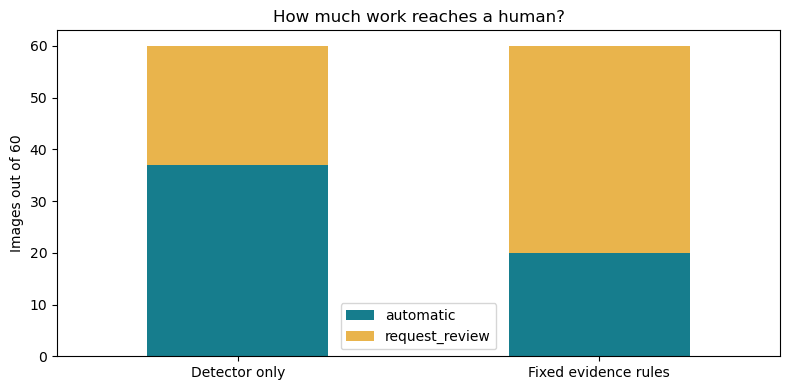

In [12]:
display(lab.breakdown(detector_predictions))
baseline_results[['automatic', 'request_review']].plot.bar(stacked=True, color=['#167d8d', '#e9b44c'], rot=0, figsize=(8, 4))
plt.ylabel('Images out of 60')
plt.title('How much work reaches a human?')
plt.tight_layout()
plt.show()

## 6. Build an agent that asks useful questions 🤖🔎

A fixed pipeline asks the same questions every time. Our agent should choose its next evidence tool based on what it has already observed—and stop or request review when more evidence will not resolve the case.

The tools are plain Python commands returning JSON. Try one below. It logs the evidence returned, not hidden reasoning. The `tool_demo` run is separate from your eventual agent run.

In [13]:
import subprocess

tool = [sys.executable, str(ROOT / 'scripts/lesson.py'), '--id', case_id, '--tool', 'fcc', '--run', 'tool_demo']
demo = subprocess.run(tool, capture_output=True, text=True, check=False)
print(demo.stdout or demo.stderr)

{
  "id": "site_004",
  "evidence_id": "site_004:fcc",
  "cached": true,
  "result": {
    "available": true,
    "matches": [
      {
        "registration": "1326645",
        "unique_id": "2726895",
        "status_code": "C",
        "constructed_date": "11/27/2024",
        "dismantled_date": "",
        "action_date": "09/26/2025",
        "city": "Comstock",
        "state": "WI",
        "county_fips": "55095",
        "height_structure_m": "76.2",
        "overall_height_agl_m": "79.2",
        "structure_type_code": "LTOWER",
        "address": "1898 5th Street, Comstock, WI  54829",
        "latitude": 45.48019444444444,
        "longitude": -92.16580555555556,
        "coordinate_type_code": "T",
        "organization_owner": "Vertical Bridge VBTS, LLC",
        "fcc_url": "https://wireless2.fcc.gov/UlsApp/AsrSearch/asrRegistration.jsp?regKey=2726895",
        "distance_m": 1.9,
        "spatial_relation": "within 100 m; possible site match",
        "constructed_after_naip

### Agent mission 1: investigate five cases 🖐️

Save the notebook and open your local coding assistant with `week10` as its workspace. Paste:

> Read `AGENT_HANDOFF.md`. Use the evidence tools to investigate `site_001` through `site_005`. Inspect the images, then choose additional evidence only where useful. Do not read `data/reference/`, manual annotations, or previous results. For each image choose `confirm`, `no_target`, or `request_review`, cite the evidence IDs actually returned, and give a short factual reason. Use run name `agent_v1` and at most five tool calls per image. Save the five decisions to `runs/agent_v1/predictions.json`, then stop so I can inspect the tool use. Do not invent missing observations.

Read the calls and reasons. Did the agent actually view the imagery? Did it confuse a missing cache with a negative search? Did it check dates? If it cannot view images in your environment, it must say so.

**Important:** Reference answers live in this repository for teaching. Asking the agent not to read them is a classroom rule, not an enforced security barrier. We are developing a workflow, not claiming a blind evaluation.

### Agent mission 2: freeze the policy, then run all 60 🚦

After inspecting the five cases, agree on the policy and paste:

> Continue `agent_v1` with the same policy. Process all candidate IDs from `data/challenge/manifest.json`, preserving the existing five decisions and tool logs. Keep the five-call budget per image, do not consult reference answers, and do not retrain. Save exactly one decision for each of the 60 IDs to `runs/agent_v1/predictions.json`. Record the policy and limitations in `run_notes.md`. Validate the output with `scripts.lesson.validate_predictions`, but leave reference scoring to me. Do not claim that an evidence-using agent must outperform the baselines.

Use a new run name if you change the policy. Running 60 cases may take longer than the class slot; the instructor can run this beforehand. We supply baseline results, **not a fabricated agent run**. If you run only five cases, the next section will clearly identify partial coverage.

Load your real agent output if it exists. There is no automatic model call in this notebook.

In [14]:
agent_file = ROOT / 'runs/agent_v1/predictions.json'
agent_predictions = lab.load(agent_file) if agent_file.exists() else None
if agent_predictions is not None:
    lab.validate_predictions(agent_predictions, require_all=False)
    print(f'Loaded {len(agent_predictions)} decisions. Full comparison requires all 60.')
else:
    print('No agent run saved yet. Complete the handoff, or continue discussing the baselines.')

No agent run saved yet. Complete the handoff, or continue discussing the baselines.


## 7. Did extra evidence actually help? ⚖️

We compare all methods on the same 60 IDs. Partial agent runs are useful for debugging, but should not appear beside full runs as though they covered the same cases.

The table below adds the agent only when its full output is present. “Request review” is not automatically an error; it is a workload decision. The unresolved references remain unresolved in the scoring.

In [15]:
comparison = baseline_results.copy()
if agent_predictions is not None and len(agent_predictions) == 60:
    comparison.loc['Evidence-using agent'] = lab.score(agent_predictions)
display(comparison)

,evaluated,automatic,request_review,coverage,resolved_automatic,wrong_automatic,false_confirms,false_rejections,selective_error,unresolved_routing
Detector only,60,37,23,0.616667,34,2,0,2,0.058824,"{'no_target': 1, 'confirm': 2, 'request_review..."
Fixed evidence rules,60,20,40,0.333333,20,0,0,0,0.000000,{'request_review': 10}


Inspect the decision breakdown. Keep the uncertain-reference row visible, rather than forcing it into a binary confusion matrix.

In [16]:
decisions_to_inspect = agent_predictions if agent_predictions else rules_predictions
display(lab.breakdown(decisions_to_inspect))
display(pd.DataFrame(decisions_to_inspect)[['id', 'action', 'reason']].head(10))

action,confirm,no_target,request_review
reference,,,
positive,20,0,10
negative,0,0,20
uncertain,0,0,10


,id,action,reason
0,site_001,request_review,"Weak, missing, or conflicting evidence."
1,site_002,request_review,"Weak, missing, or conflicting evidence."
2,site_003,request_review,"Weak, missing, or conflicting evidence."
3,site_004,request_review,"Weak, missing, or conflicting evidence."
4,site_005,request_review,"Weak, missing, or conflicting evidence."
5,site_006,confirm,High detector score and nearby temporally comp...
6,site_007,request_review,"Weak, missing, or conflicting evidence."
7,site_008,request_review,"Weak, missing, or conflicting evidence."
8,site_009,request_review,"Weak, missing, or conflicting evidence."
9,site_010,confirm,High detector score and nearby temporally comp...


### Audit the story, not just the score 🧾

Open `runs/agent_v1/tool_calls.jsonl`. Pick two decisions and check each claim against the evidence actually returned.

- Was the cited record the same site, or merely nearby?
- Did the dates make sense?
- Was the image actually inspected?
- Did the reason admit missing evidence?
- Was the target definition applied consistently?

For any real agent run, compare its recorded tool calls with the five-call budget. The wrapper enforces this within a run; it cannot prevent an assistant with unrestricted file access from bypassing the wrapper. Do not treat the log as proof of technical isolation.

Review all requests for human help, plus a small random sample of automatic decisions. Preserve the original predictions and supplied reference labels; save adjudicated changes as a new annotation version. Otherwise we would be moving the answer key after seeing the result.

## 8. Your five-minute research briefing 🎤

Use three image examples and the results table to explain:

1. **The task:** What counts as a target, and what made manual labelling difficult?
2. **The method:** Which evidence did your agent choose, and when did it stop?
3. **The result:** How many decisions were automatic, how many were wrong, and how many needed review?
4. **The failure:** Show one misleading source or unfaithful explanation. What would fix it?
5. **The limit:** Why does this classroom sample not establish national performance?

**Success is not “the agent always wins”.** A useful result can be finding that additional evidence prevents confident mistakes—or that our agent merely adds complexity without reducing review work. 🧠

## Optional side quests 🎮

- **Interface designer:** add an uncertainty queue, image zoom, or keyboard navigation. Verify box coordinates still round-trip correctly.
- **Evidence detective:** add one genuinely new source. Report access, date, missing coverage, and actual usefulness; do not substitute an invented response.
- **Policy scientist:** vary one decision threshold and plot coverage against selective error. Label the exercise exploratory because the answers are already visible.
- **Annotation researcher:** have two reviewers independently label the same five images. Separate disagreements about object identity from disagreements about box extent.
- **Evaluation designer:** propose an unseen, geographically separated sample for a later test, with reference labels outside the agent's workspace.

Do not retrain on the classroom references and then report performance on those same images as an unseen test.

## Sources, provenance, and credits 📚

- **Project material:** the instructor's `us_tower_expansion` project; source review filenames, original image hashes, selection rules, and known membership are recorded in `data/reference/provenance.json`. Human uncertainty is preserved. See `data/README.md` for packaging limitations.
- **Aerial imagery:** USDA National Agriculture Imagery Program (NAIP), RGB classroom derivatives at unchanged pixel dimensions. [USDA dataset record](https://catalog.data.gov/dataset/national-agriculture-imagery-program-naip-imagery). Credit USDA Farm Production and Conservation / geospatial imagery providers recorded in the source metadata.
- **Candidate tags:** © OpenStreetMap contributors, [Open Database License and attribution](https://www.openstreetmap.org/copyright). Tags are source evidence, not verified reference labels.
- **Structure evidence:** cached FCC Antenna Structure Registration fields from the source project. [FCC discussion of registration scope](https://docs.fcc.gov/public/attachments/FCC-10-53A1_Rcd.pdf). FCC registration does not establish cellular use.
- **Annotation workflow:** [VGG Image Annotator](https://robots.ox.ac.uk/~vgg/software/via/index.html), developed by the Visual Geometry Group, University of Oxford. Our small browser interface exports VIA-style rectangle records; it does not bundle or replace the upstream application.

No live street-level imagery, lidar, permits, or independent owner listings have been fetched for this lesson. Missing channels remain missing. The repository contains no trained weights or data-service credentials.